In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)
n_samples = 1200

# Simulating realistic student attributes (including new metrics)
study_hours = np.random.normal(loc=14, scale=4, size=n_samples).clip(2, 35)       # Weekly study hours
attendance = np.random.normal(loc=82, scale=10, size=n_samples).clip(40, 100)     # Attendance percentage
past_gpa = np.random.normal(loc=7.2, scale=1.4, size=n_samples).clip(3.0, 10.0)    # Past academic score / GPA
sleep_hours = np.random.normal(loc=7.2, scale=1.1, size=n_samples).clip(4, 10)     # Daily sleep hours
extracurricular = np.random.choice([0, 1], size=n_samples, p=[0.55, 0.45])         # 0 = No, 1 = Yes

# New Features: Family Relations and Social Engagement (Ratings 1 to 5)
family_relations = np.random.randint(1, 6, size=n_samples)
social_engagement = np.random.randint(1, 6, size=n_samples)

# Generating target logic (passing probability influenced by features + realistic noise)
score_weight = (
    (0.04 * study_hours) +
    (0.04 * attendance) +
    (0.10 * past_gpa) +
    (0.02 * sleep_hours) +
    (0.03 * family_relations) +
    (0.03 * social_engagement)
)
normalized_score = (score_weight - score_weight.min()) / (score_weight.max() - score_weight.min())
noise = np.random.normal(0, 0.06, n_samples)
final_prob = (normalized_score + noise).clip(0, 1)

# Target variable: 1 if student passes, 0 if at-risk
passed = (final_prob > 0.52).astype(int)

df = pd.DataFrame({
    'Study_Hours_Weekly': study_hours,
    'Attendance_Pct': attendance,
    'Past_GPA': past_gpa,
    'Sleep_Hours_Daily': sleep_hours,
    'Extracurricular': extracurricular,
    'Family_Relations': family_relations,
    'Social_Engagement': social_engagement,
    'Passed': passed
})

print(df.head())
print(f"\nDataset Shape: {df.shape}")
print(f"Class Distribution:\n{df['Passed'].value_counts(normalize=True).mul(100).round(2)}%")

   Study_Hours_Weekly  Attendance_Pct  Past_GPA  Sleep_Hours_Daily  \
0           15.986857       83.252245  6.189567           6.293671   
1           13.446943       77.705945  7.447549           6.408980   
2           16.590754       83.222975  6.434648           9.454793   
3           20.092119       87.432980  6.819683           7.200751   
4           13.063387       82.488601  9.542833           8.060343   

   Extracurricular  Family_Relations  Social_Engagement  Passed  
0                0                 1                  2       1  
1                1                 2                  4       0  
2                0                 5                  5       1  
3                0                 3                  5       1  
4                0                 4                  4       1  

Dataset Shape: (1200, 8)
Class Distribution:
Passed
0    57.25
1    42.75
Name: proportion, dtype: float64%


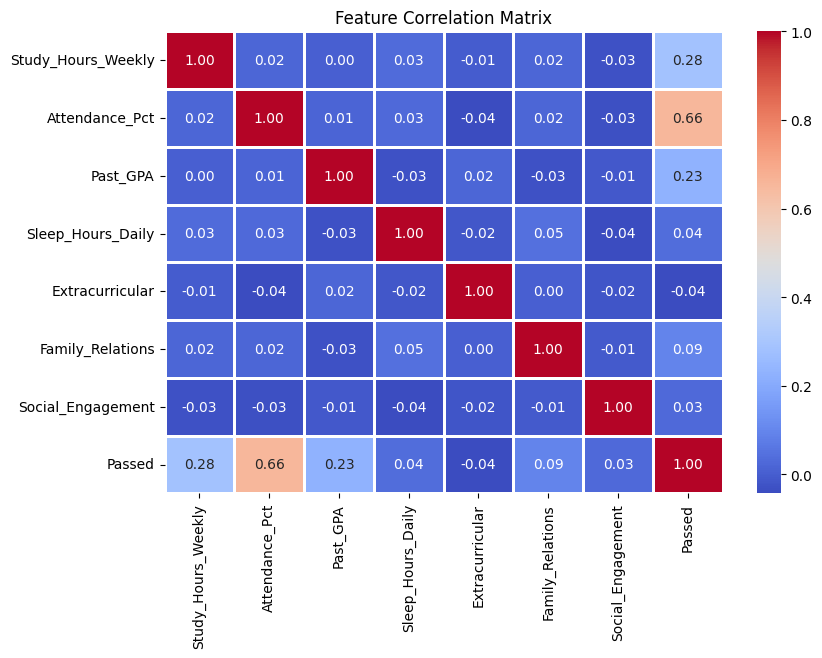

In [3]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.8)
plt.title("Feature Correlation Matrix")
plt.show()

In [4]:
# Separate features (X) and target (y)
X = df.drop(columns=['Passed'])
y = df['Passed']

# Split into 80% training set and 20% testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Normalize numerical features so they contribute equally to the model
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set rows: {X_train.shape[0]}")
print(f"Testing set rows: {X_test.shape[0]}")

Training set rows: 960
Testing set rows: 240


In [5]:
# Initialize and train a Random Forest Classifier
model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model training completed successfully!\n")

# Display which features had the most predictive power
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Feature Importances:")
print(importances)

Model training completed successfully!

Feature Importances:
Attendance_Pct        0.561397
Study_Hours_Weekly    0.163050
Past_GPA              0.138086
Sleep_Hours_Daily     0.071560
Family_Relations      0.030086
Social_Engagement     0.025577
Extracurricular       0.010245
dtype: float64


Model Accuracy: 92.08%

Classification Report:
              precision    recall  f1-score   support

 At-Risk (0)       0.93      0.93      0.93       137
  Passed (1)       0.90      0.91      0.91       103

    accuracy                           0.92       240
   macro avg       0.92      0.92      0.92       240
weighted avg       0.92      0.92      0.92       240



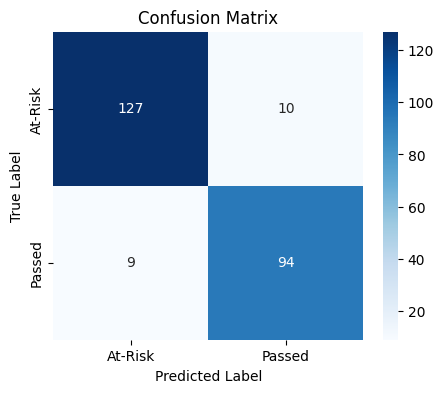

In [6]:
# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# Print overall accuracy and detailed classification report
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['At-Risk (0)', 'Passed (1)']))

# Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['At-Risk', 'Passed'], yticklabels=['At-Risk', 'Passed'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [7]:
# Define a new student profile: [Study_Hours, Attendance_Pct, Past_GPA, Sleep_Hours, Extracurricular, Family_Relations, Social_Engagement]
new_student = [[8.5, 65.0, 5.5, 6.0, 0, 3, 2]]  # Example profile

# Scale input data using the pre-fitted scaler
new_student_scaled = scaler.transform(new_student)

# Predict outcome and probability
prediction = model.predict(new_student_scaled)[0]
probabilities = model.predict_proba(new_student_scaled)[0]

status = "✅ On-Track (Pass)" if prediction == 1 else "⚠️ At-Risk (Needs Intervention)"
print(f"Prediction Result: {status}")
print(f"Confidence Score -> At-Risk: {probabilities[0]*100:.1f}% | Pass: {probabilities[1]*100:.1f}%")

Prediction Result: ⚠️ At-Risk (Needs Intervention)
Confidence Score -> At-Risk: 97.1% | Pass: 2.9%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [8]:
# Save model, scaler, and dataset
joblib.dump(model, 'student_model.pkl')
joblib.dump(scaler, 'feature_scaler.pkl')
print("\nModel and scaler successfully saved as .pkl files!")

df.to_csv('student_performance_dataset.csv', index=False)
print("Dataset successfully saved as student_performance_dataset.csv!")


Model and scaler successfully saved as .pkl files!
Dataset successfully saved as student_performance_dataset.csv!
